Load the Graph

In [5]:
import pandas as pd

SNAP_URL = "https://snap.stanford.edu/data/soc-sign-bitcoinotc.csv.gz"

df = pd.read_csv(
    SNAP_URL,
    compression="gzip",
    header=None,
    names=["source", "target", "sign", "timestamp"]
)

print(df.head())
print(df.shape)

   source  target  sign     timestamp
0       6       2     4  1.289242e+09
1       6       5     2  1.289242e+09
2       1      15     1  1.289243e+09
3       4       3     7  1.289245e+09
4      13      16     8  1.289254e+09
(35592, 4)


Graph Representation

In [6]:
#converting dataframe into dictionary graph
graph = {}

# changed this df to random_df
for _, row in df.iterrows(): #iterrows() give index and row we dont care about index so we used _
    u = int(row["source"])
    v = int(row["target"])
    signed_edge_weight = row["sign"]/10

    if u not in graph:
        graph[u] = []

    graph[u].append((v, signed_edge_weight))


for node, edges in list(graph.items())[:5]:
  print(node, edges) #graph[node] = [(neighbor, weight), ...]

6 [(2, np.float64(0.4)), (5, np.float64(0.2)), (4, np.float64(0.2)), (7, np.float64(0.5)), (114, np.float64(0.2)), (32, np.float64(0.1)), (173, np.float64(0.3)), (258, np.float64(0.1)), (268, np.float64(0.3)), (219, np.float64(0.4)), (198, np.float64(0.2)), (35, np.float64(0.4)), (664, np.float64(0.1)), (937, np.float64(0.1)), (384, np.float64(0.6)), (521, np.float64(0.1)), (280, np.float64(0.1)), (687, np.float64(0.1)), (1386, np.float64(0.3)), (537, np.float64(0.5)), (1317, np.float64(0.2)), (1566, np.float64(0.1)), (2034, np.float64(0.1)), (2455, np.float64(0.1)), (1383, np.float64(-1.0)), (1810, np.float64(0.3)), (2028, np.float64(0.1)), (1363, np.float64(0.8)), (10, np.float64(0.3)), (1, np.float64(0.8)), (1018, np.float64(0.1)), (1832, np.float64(0.1)), (1624, np.float64(0.3)), (550, np.float64(0.1)), (1331, np.float64(-1.0)), (2642, np.float64(0.4)), (856, np.float64(0.8)), (2188, np.float64(0.9)), (2187, np.float64(0.5)), (1752, np.float64(0.5))]
1 [(15, np.float64(0.1)), (5, n

Finding Highest Degree Node

In [7]:
#calculate degree
degree = {}

for node, edges in graph.items():
    degree[node] = len(edges)

D = 5 #top k degree we want

top_k_nodes = sorted(
    degree,
    key=degree.get,
    reverse=True
)[:D]

for node in top_k_nodes:
    print(node, degree[node])  #node and it's total degree

35 763
2642 406
1810 404
2125 397
2028 293


Making Domains

In [8]:
import numpy as np

nodes = set(df["source"].astype(int)) | set(df["target"].astype(int)) #nodes that can appear only as a target (v).

nodes = list(nodes)
print(len(nodes))
k = 5 #domains we want

np.random.shuffle(nodes)

domains = {}

for i, node in enumerate(nodes): #loop over iterable keeping track of index too and also value which is node
    domains[node] = i % k

print(list(domains.items())[:10])

for instance in range(k): #how many node each instance has
    count = sum(1 for d in domains.values() if d == instance)
    print("Instance", instance, ":", count, "nodes")

5881
[(4995, 0), (4356, 1), (423, 2), (2693, 3), (3782, 4), (4701, 0), (5415, 1), (5396, 2), (1825, 3), (1541, 4)]
Instance 0 : 1177 nodes
Instance 1 : 1176 nodes
Instance 2 : 1176 nodes
Instance 3 : 1176 nodes
Instance 4 : 1176 nodes


Fediverse Matrix

In [9]:
F = np.random.uniform(0, 1, size=(k, k))

# Same-instance relationship
np.fill_diagonal(F, 1.0)

print(F)

[[1.         0.37516264 0.134694   0.6349447  0.85260406]
 [0.91179316 1.         0.46173714 0.09821049 0.91004214]
 [0.76015307 0.21109064 1.         0.92750756 0.3908683 ]
 [0.15986351 0.14947545 0.87536592 1.         0.03025794]
 [0.80306524 0.72201096 0.63606993 0.11014681 1.        ]]


Diffusion Model

In [10]:
def diffusion_model(
    graph,
    seeds,
    domains,
    threshold_for_cross_domain,
    F,
    iterations,
    learning_rate,
    user_threshold
):

    # Initial state
    positive_active = set(seeds)
    negative_active = set()

    # Initially, only seeds are allowed to propagate
    current_positive = set(seeds)
    current_negative = set()

    for iteration in range(iterations):


        # 1. Same-domain diffusion
        positive_active, negative_active, same_new_positive, same_new_negative = (
            same_domain_diffusion(
                graph,
                positive_active,
                negative_active,
                domains,
                current_positive,
                current_negative
            )
        )

        # 2. Cross-domain diffusion
        positive_active, negative_active, domain_influence, cross_new_positive, cross_new_negative = (
            cross_domain_diffusion(
                graph,
                positive_active,
                negative_active,
                domains,
                threshold_for_cross_domain,
                F,
                current_positive,
                current_negative,
                user_threshold
            )
        )



        # 3. Update federation
        F = update_federation(
            F,
            domain_influence,
            learning_rate
        )

        # Combine newly activated nodes from both diffusion mechanisms
        current_positive = same_new_positive | cross_new_positive
        current_negative = same_new_negative | cross_new_negative

    return positive_active, negative_active

Same Domain Diffusion

In [11]:
#We shouldn't immediately put a node into new_positive or new_negative when an edge succeeds, because the same node may receive influence from several active nodes during the same round.

def same_domain_diffusion(graph, positive_active, negative_active, domains, current_positive, current_negative):

    influence = {} #all successful influence attempts received by each node during this round.

    current_active = current_positive | current_negative  #set union combining both positive and negaitve active

    for u in current_active:

        for v, signed_edge_weight in graph.get(u, []): #for every currently active node u , examine it's outgoing edge

            # Same-domain only
            if domains[u] != domains[v]:
                continue

            # Already influenced
            if v in positive_active or v in negative_active:
                continue

            probability = abs(signed_edge_weight)

            # IC attempt
            if np.random.random() < probability:

                if v not in influence:
                    influence[v] = []

                source_polarity = 1 if u in current_positive else -1
                generated_influence = source_polarity * signed_edge_weight
                influence[v].append(generated_influence)

    # Decide final influence after receiving all successful attempts
    new_positive = set()
    new_negative = set()

    for v, weights in influence.items():

        strongest_weight = max(weights, key=abs) #check maximum influcence coming

        if strongest_weight > 0:
            new_positive.add(v)
        elif strongest_weight < 0:
            new_negative.add(v)

    positive_active.update(new_positive)
    negative_active.update(new_negative)

    return positive_active, negative_active, new_positive, new_negative

Cross Domain Diffusion

In [12]:
def cross_domain_diffusion(
    graph,
    positive_active,
    negative_active,
    domains,
    threshold_for_cross_domain,
    F,
    current_positive,
    current_negative,
    user_threshold
):
    influence = {}
    domain_influence = {} #for fedration matrix change

    current_active = current_positive | current_negative

    for u in current_active:

        for v, signed_edge_weight in graph.get(u, []):

            # Only cross-domain edges
            if domains[u] == domains[v]:
                continue

            # Already influenced nodes
            if v in positive_active or v in negative_active:
                continue

            # Federation relationship
            federation_weight = F[domains[u]][domains[v]]

            # Cross-domain influence
            source_polarity = 1 if u in current_positive else -1

            influence_value = (
                source_polarity
                * signed_edge_weight
                * federation_weight
            )

            #for fedration matix change
            source_domain = domains[u]
            target_domain = domains[v]

            key = (source_domain, target_domain)

            if key not in domain_influence:
                domain_influence[key] = []

            domain_influence[key].append(influence_value)

            '''
              domain_influence = {
                  (0, 1): [0.4, 0.2, -0.1, 0.5],
                  (0, 2): [-0.6, -0.4, 0.2],
                  (1, 3): [0.3, 0.7]
              }
            '''

            if v not in influence:
                influence[v] = []

            influence[v].append(influence_value)

    new_positive = set()
    new_negative = set()

    for v, influences in influence.items():

        # Separate positive and negative influence
        positive_influence = sum(
            x for x in influences if x > 0
        )

        negative_influence = sum(
            abs(x) for x in influences if x < 0
        )

        # LT activation condition
        effective_threshold = max(
          threshold_for_cross_domain,
          user_threshold[v]
        )

        if max(positive_influence, negative_influence) >= effective_threshold:

            if positive_influence > negative_influence:
                new_positive.add(v)

            elif negative_influence > positive_influence:
                new_negative.add(v)

    positive_active.update(new_positive)
    negative_active.update(new_negative)

    return positive_active, negative_active, domain_influence, new_positive, new_negative

Update Fedration Matrix

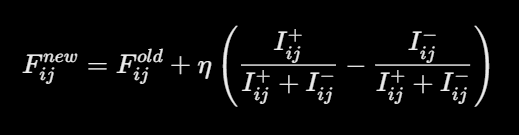

In [13]:
import numpy as np

def update_federation(F, domain_influence, learning_rate=0.1):

    for (source_domain, target_domain), influences in domain_influence.items(): #going through every domain pair

        '''
        source_domain = 0
        target_domain = 1

        influences = [0.4, 0.2, -0.1, 0.5]
        '''

        positive_influence = sum(
            x for x in influences if x > 0
        )

        negative_influence = sum(
            abs(x) for x in influences if x < 0
        )

        total_influence = positive_influence + negative_influence

        # No influence between these domains
        if total_influence == 0:
            continue

        # Fractions
        positive_fraction = positive_influence / total_influence
        negative_fraction = negative_influence / total_influence

        # Positive → increase F
        # Negative → decrease F
        net_fraction = positive_fraction - negative_fraction

        F[source_domain][target_domain] += (
            learning_rate * net_fraction
        )

        # Keep federation score between 0 and 1
        F[source_domain][target_domain] = np.clip(
            F[source_domain][target_domain],
            0,
            1
        )

    return F

creating user threshold for cross domain

In [14]:
user_threshold = {
    node: np.random.uniform(0, 1)
    for node in domains
}

Calling Diffuison main

In [15]:
threshold_for_cross_domain = 0.3

positive, negative = diffusion_model(
    graph,
    top_k_nodes,
    domains,
    threshold_for_cross_domain,
    F,
    10,
    0.1,
    user_threshold

)

 #  iterations=10,
 # learning_rate=0.1,

total = len(positive | negative)

print("Positive nodes:", len(positive))
print("Negative nodes:", len(negative))
print("Total influenced nodes:", total)

print("Positive edges:", (df["sign"] > 0).sum())
print("Negative edges:", (df["sign"] < 0).sum())

print("Positive edge percentage:",
      (df["sign"] > 0).mean() * 100)

print("Negative edge percentage:",
      (df["sign"] < 0).mean() * 100)

print("Average positive weight:",
      df.loc[df["sign"] > 0, "sign"].mean() / 10)

print("Average negative magnitude:",
      abs(df.loc[df["sign"] < 0, "sign"].mean() / 10))

print("Max positive weight:",
      df.loc[df["sign"] > 0, "sign"].max() / 10)

print("Max negative magnitude:",
      abs(df.loc[df["sign"] < 0, "sign"].min() / 10))

Positive nodes: 671
Negative nodes: 550
Total influenced nodes: 1221
Positive edges: 32029
Negative edges: 3563
Positive edge percentage: 89.98932344347045
Negative edge percentage: 10.010676556529557
Average positive weight: 0.19653126853788755
Average negative magnitude: 0.7557395453269716
Max positive weight: 1.0
Max negative magnitude: 1.0
